# Assignment 5: Email Spam Detection using KNN and SVM

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

In [2]:
df = pd.read_csv("emails.csv")
print(df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df[["Email No.", "the", "to", "ect", "and", "Prediction"]].head()

(5172, 3002)
Missing values: 0


Duplicate rows: 0


,Email No.,the,to,ect,and,Prediction
0,Email 1,0,0,1,0,0
1,Email 2,8,13,24,6,0
2,Email 3,0,0,1,0,0
3,Email 4,0,5,22,0,0
4,Email 5,7,6,17,1,0


Shape after preprocessing: (5172, 3002)


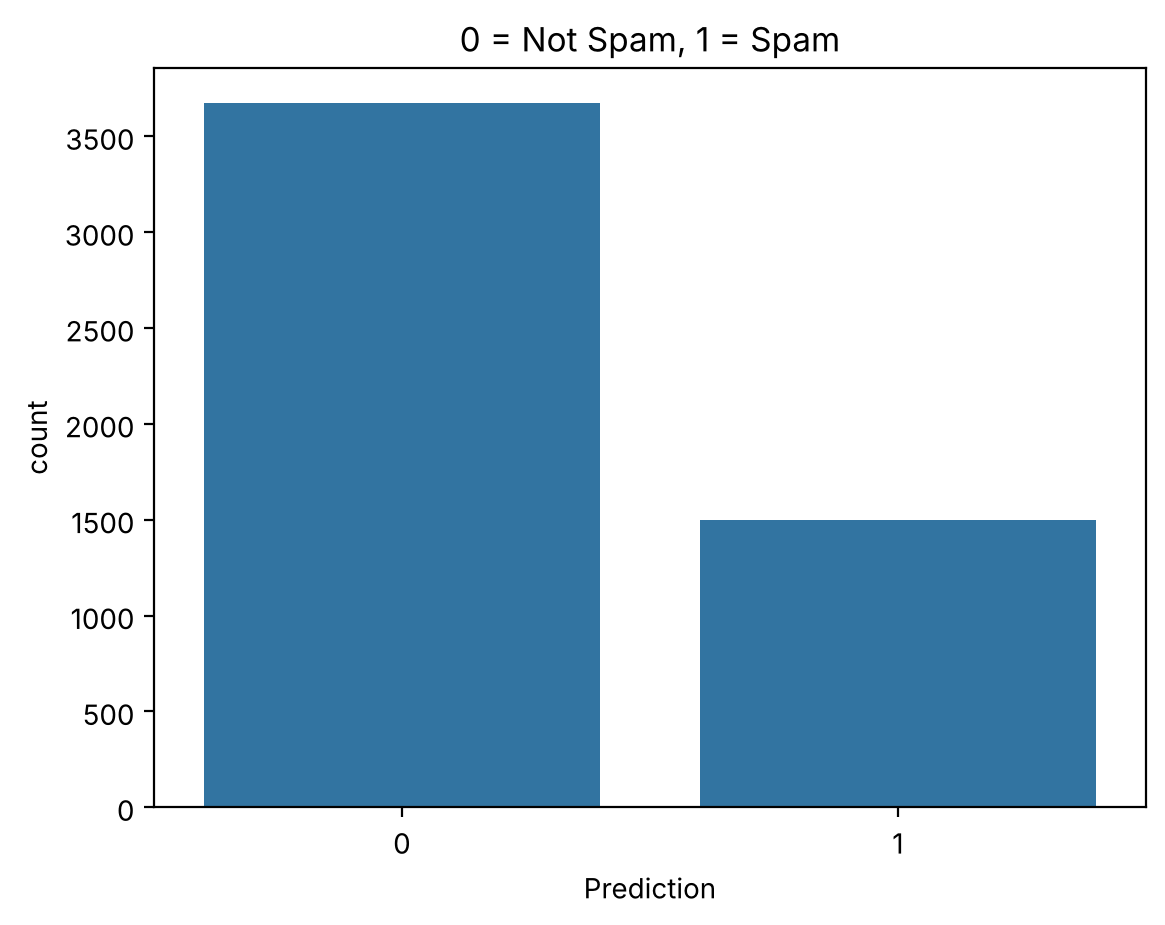

Prediction
0    3672
1    1500
Name: count, dtype: int64


In [3]:
df = df.dropna().drop_duplicates()
print("Shape after preprocessing:", df.shape)
sns.countplot(x=df["Prediction"]); plt.title("0 = Not Spam, 1 = Spam"); plt.show()
print(df["Prediction"].value_counts())

In [4]:
X = df.drop(["Email No.", "Prediction"], axis=1)
y = df["Prediction"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training:", X_train.shape, "| Testing:", X_test.shape)

Training: (4137, 3000) | Testing: (1035, 3000)


In [5]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## K-Nearest Neighbors

In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

## Support Vector Machine

In [7]:
svm = SVC(kernel='linear', random_state=42)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

## Performance analysis

KNN PERFORMANCE
  Accuracy: 83.38 %
  Error Rate: 16.62 %
  Precision: 64.35 %
  Recall: 95.67 %
  F1 Score: 76.94 %
  Confusion Matrix:
 [[576 159]
 [ 13 287]] 



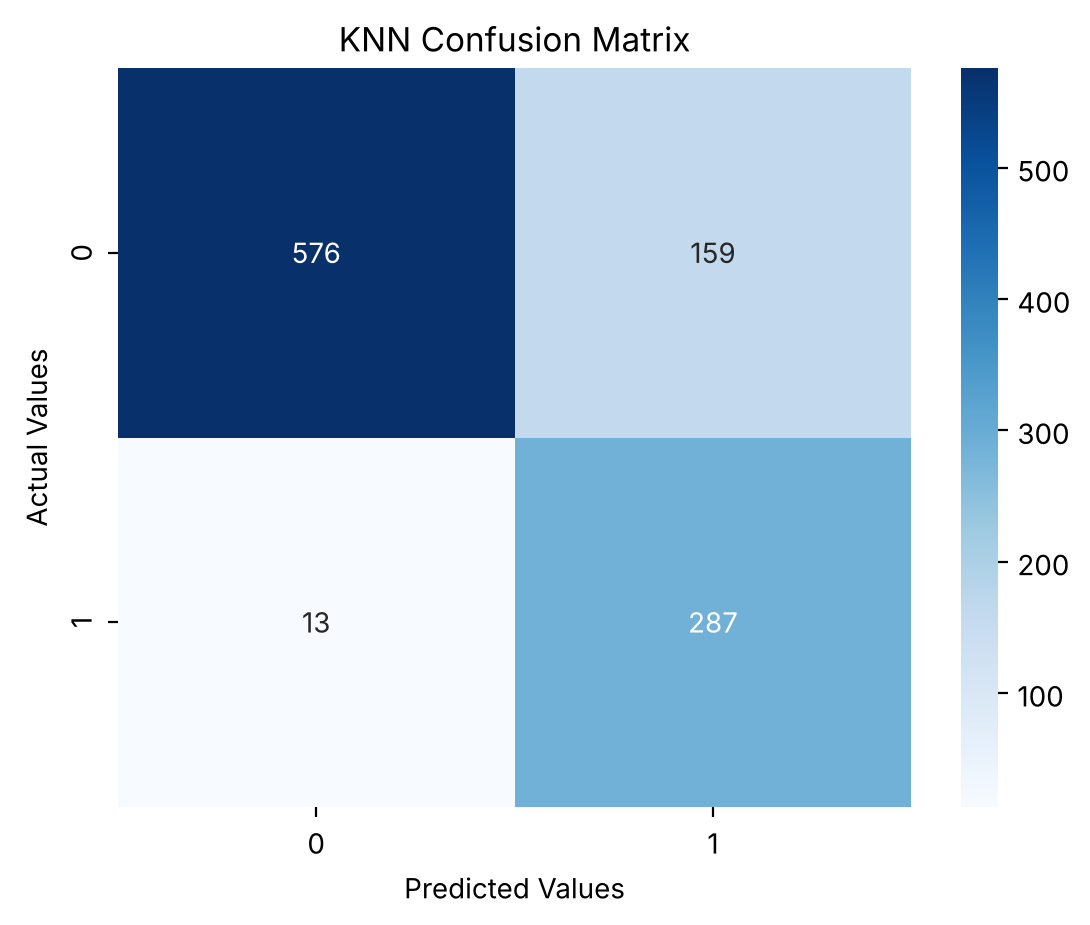

SVM PERFORMANCE
  Accuracy: 95.07 %
  Error Rate: 4.93 %
  Precision: 91.36 %
  Recall: 91.67 %
  F1 Score: 91.51 %
  Confusion Matrix:
 [[709  26]
 [ 25 275]] 



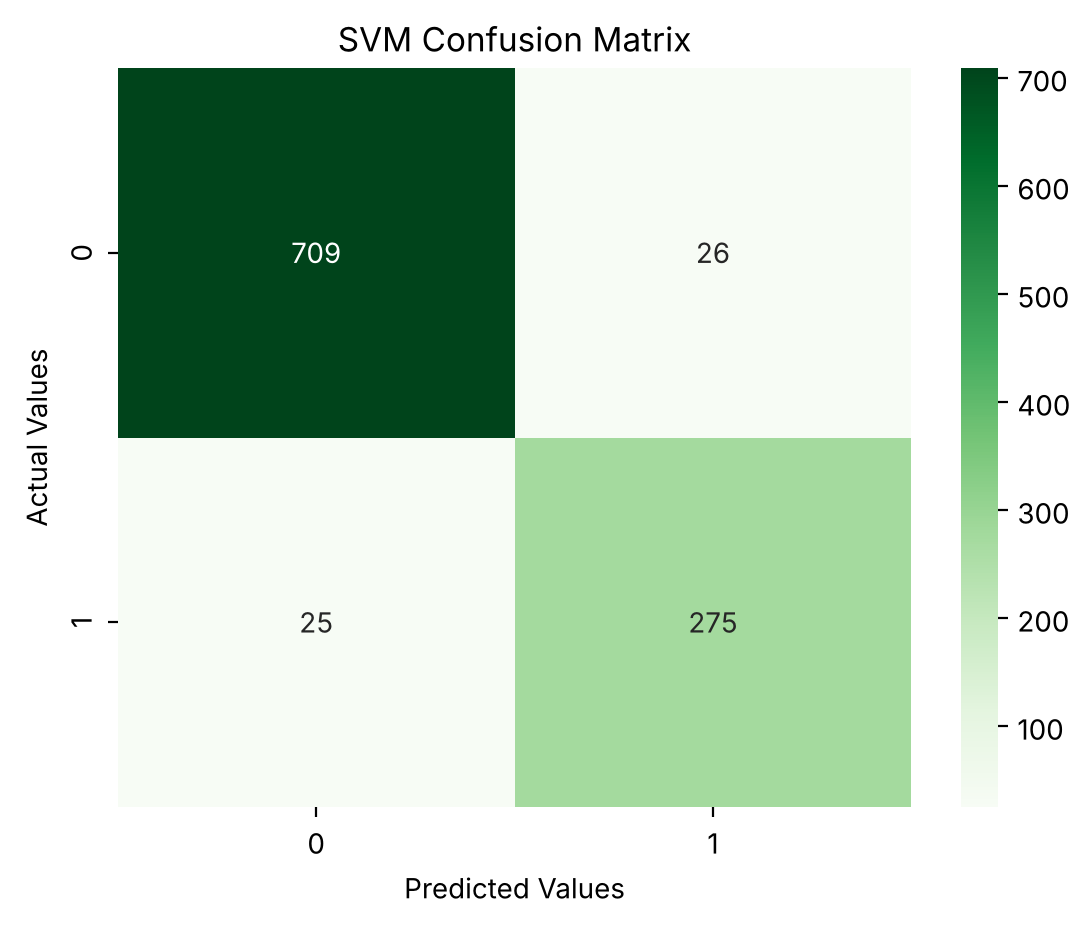

In [8]:
def report(name, y_true, y_pred, cmap):
    acc = accuracy_score(y_true, y_pred)
    res = {"Algorithm": name, "Accuracy": acc*100, "Error Rate": (1-acc)*100,
           "Precision": precision_score(y_true, y_pred, zero_division=0)*100,
           "Recall": recall_score(y_true, y_pred, zero_division=0)*100,
           "F1 Score": f1_score(y_true, y_pred, zero_division=0)*100}
    cm = confusion_matrix(y_true, y_pred)
    print(f"{name} PERFORMANCE")
    for k, v in res.items():
        if k != "Algorithm": print(f"  {k}: {v:.2f} %")
    print("  Confusion Matrix:\n", cm, "\n")
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap)
    plt.xlabel("Predicted Values"); plt.ylabel("Actual Values"); plt.title(f"{name} Confusion Matrix")
    plt.show()
    return res

knn_res = report("KNN", y_test, knn_pred, "Blues")
svm_res = report("SVM", y_test, svm_pred, "Greens")

  Algorithm  Accuracy  Error Rate  Precision  Recall  F1 Score
0       KNN     83.38       16.62      64.35   95.67     76.94
1       SVM     95.07        4.93      91.36   91.67     91.51


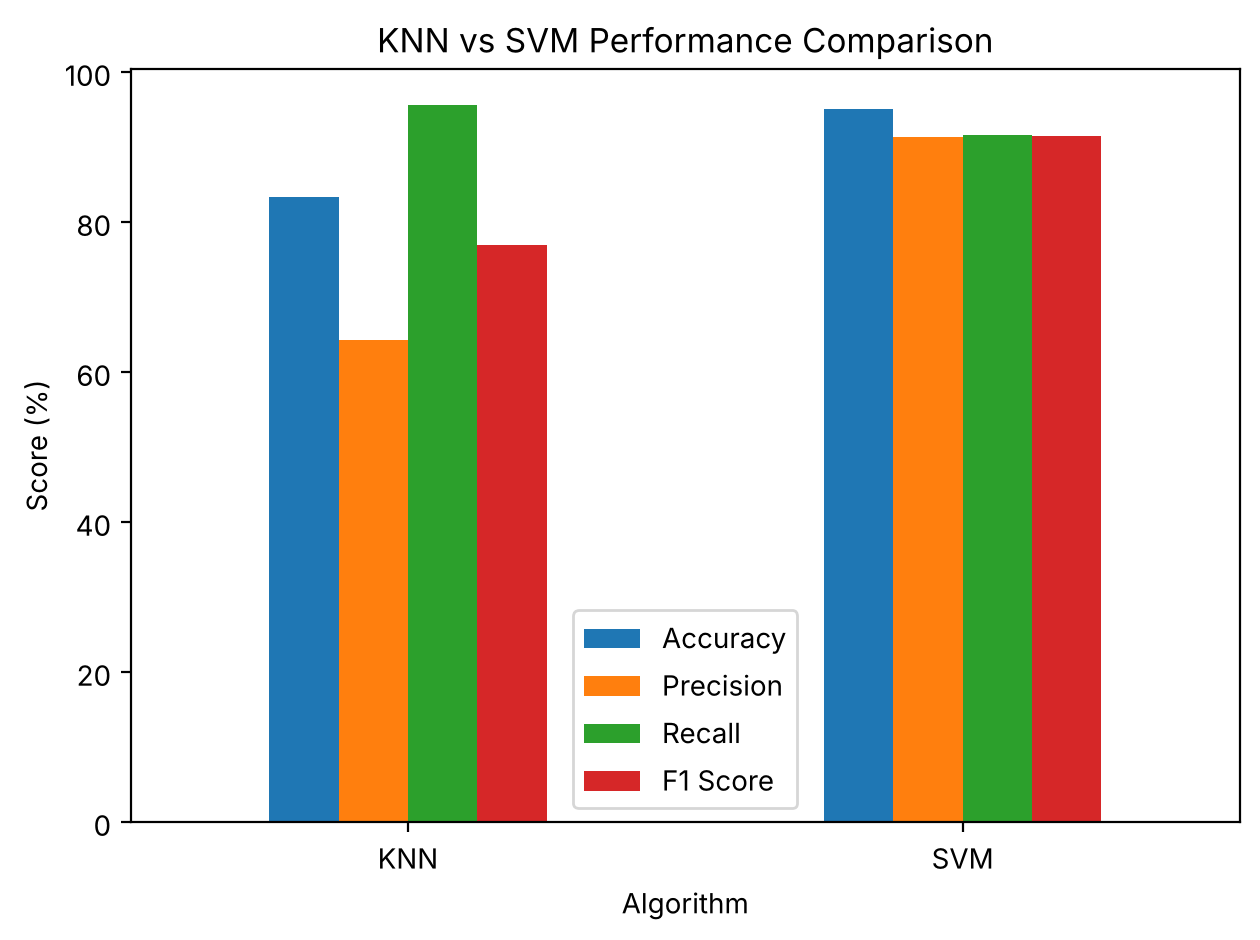

In [9]:
comparison = pd.DataFrame([knn_res, svm_res])
print(comparison.round(2))
comparison.plot(x="Algorithm", y=["Accuracy", "Precision", "Recall", "F1 Score"], kind="bar")
plt.ylabel("Score (%)"); plt.title("KNN vs SVM Performance Comparison"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

In [10]:
best = comparison.loc[comparison["F1 Score"].idxmax(), "Algorithm"]
print(f"{best} performs better based on F1 Score.")

SVM performs better based on F1 Score.
